# Chapter 5. Evaluation

## 5.2 Comparison of Parameter-Selection Strategies

## 5.2.1 Adaptive vs Fixed

Adaptive and Fixed are compared on the same 100 test images and noise levels.

In [5]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoising_config import (
    FIXED_PRIMARY_PARAMETERS, FLAT_FRACTION, METHOD_LABELS, METHOD_ORDER,
    PRIMARY_PARAMETER_NAMES, denoise_fixed, denoise_mapped, get_fixed_parameters
)
from src.noise import add_gaussian_noise
from src.noise_level_estimators import edge_aware_laplacian_noise_estimate
from src.utils import load_grayscale_image

In [6]:
noise_levels = list(range(2, 16))
seed = 42
num_test_images = 100
n_jobs = 16

test_dir = project_dir / "data" / "test"
result_dir = project_dir / "results" / "Chapter5_CompareSelectionStrategies"
result_dir.mkdir(parents=True, exist_ok=True)

missing_fixed = [method for method in METHOD_ORDER if FIXED_PRIMARY_PARAMETERS[method] is None]
if missing_fixed:
    raise ValueError("Set the fixed primary parameters in denoising_config.py: " + ", ".join(missing_fixed))

fixed_rows = []
for method in METHOD_ORDER:
    parameters = get_fixed_parameters(method)
    parameter_name = PRIMARY_PARAMETER_NAMES[method]
    fixed_rows.append({
        "Method": METHOD_LABELS[method],
        "Fixed parameter": parameter_name,
        "Value": parameters[parameter_name]
    })

print("Test directory:", test_dir)
print("Noise levels (%):", noise_levels)
print("Flat-region fraction:", f"{FLAT_FRACTION:.0%}")
display(pd.DataFrame(fixed_rows))

Test directory: D:\MScProject\data\test
Noise levels (%): [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Flat-region fraction: 4%


,Method,Fixed parameter,Value
0,Anisotropic diffusion,kappa,0.1300
1,Total variation,weight,0.0675
2,Bilateral filtering,sigma_color,0.1000
3,Non-local means,h,0.1050


In [7]:
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(test_dir.rglob(pattern))

image_files = sorted(set(image_files))
if len(image_files) != num_test_images:
    raise FileNotFoundError(f"Expected {num_test_images} test images, but found {len(image_files)} in {test_dir}")

test_images = [(image_file.stem, load_grayscale_image(image_file)) for image_file in image_files]

for image_name, clean_image in test_images:
    if clean_image.ndim != 2:
        raise ValueError(f"{image_name} is not a grayscale image")
    if clean_image.min() < 0 or clean_image.max() > 1:
        raise ValueError(f"{image_name} is not normalised to [0, 1]")

print("Number of test images:", len(test_images))

Number of test images: 100


### Test evaluation

Adaptive uses the estimated noise level. Fixed uses one fixed primary parameter.

In [8]:
def make_case_seed(image_index, noise_percent):
    noise_index = noise_levels.index(noise_percent)
    return seed + noise_index * num_test_images + image_index


def evaluate_test_case(image_index, image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_percent / 100, seed=make_case_seed(image_index, noise_percent)
    ).astype(np.float32)

    estimated_percent = 100 * float(
        edge_aware_laplacian_noise_estimate(noisy_image, flat_fraction=FLAT_FRACTION)
    )

    rows = []
    for method in METHOD_ORDER:
        adaptive_image = denoise_mapped(noisy_image, method, estimated_percent)
        fixed_image = denoise_fixed(noisy_image, method)

        for strategy, denoised_image in [("Adaptive", adaptive_image), ("Fixed", fixed_image)]:
            if denoised_image.shape != clean_image.shape:
                raise ValueError(f"{method} returned an unexpected shape")
            if not np.isfinite(denoised_image).all():
                raise ValueError(f"{method} returned a non-finite value")

            psnr_value = peak_signal_noise_ratio(clean_image, denoised_image, data_range=1.0)
            ssim_value = structural_similarity(clean_image, denoised_image, data_range=1.0)
            rows.append({
                "image": image_name, "image_index": image_index,
                "true_noise_percent": noise_percent, "estimated_noise_percent": estimated_percent,
                "method": method, "strategy": strategy, "psnr": psnr_value, "ssim": ssim_value
            })

    return rows

In [9]:
case_outputs = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_test_case)(image_index, image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_index, (image_name, clean_image) in enumerate(test_images)
)

test_results = pd.DataFrame([row for case_rows in case_outputs for row in case_rows])
test_results = test_results.sort_values(
    ["method", "strategy", "true_noise_percent", "image_index"]
).reset_index(drop=True)

expected_rows = num_test_images * len(noise_levels) * len(METHOD_ORDER) * 2
if len(test_results) != expected_rows:
    raise RuntimeError(f"Expected {expected_rows} rows, but obtained {len(test_results)}")

print("Completed image-noise cases:", len(case_outputs))
print("Completed PSNR measurements:", len(test_results))
display(test_results.head())

[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:   10.5s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   37.4s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:  1.1min
[Parallel(n_jobs=16)]: Done 418 tasks      | elapsed:  1.8min
[Parallel(n_jobs=16)]: Done 616 tasks      | elapsed:  2.6min
[Parallel(n_jobs=16)]: Done 850 tasks      | elapsed:  3.7min
[Parallel(n_jobs=16)]: Done 1120 tasks      | elapsed:  4.8min


Completed image-noise cases: 1400
Completed PSNR measurements: 11200


[Parallel(n_jobs=16)]: Done 1400 out of 1400 | elapsed:  6.0min finished


,image,image_index,true_noise_percent,estimated_noise_percent,method,strategy,psnr,ssim
0,001,0,2,2.930928,AD,Adaptive,32.579760,0.927210
1,002,1,2,2.051222,AD,Adaptive,37.291542,0.955519
2,003,2,2,2.077381,AD,Adaptive,37.171387,0.945708
3,004,3,2,2.058982,AD,Adaptive,37.324663,0.957255
4,005,4,2,2.129085,AD,Adaptive,35.361967,0.960693


In [10]:
group_columns = ["method", "strategy", "true_noise_percent"]

level_summary = test_results.groupby(group_columns, as_index=False).agg(
    psnr=("psnr", "mean"), ssim=("ssim", "mean")
)
psnr_summary = level_summary[group_columns + ["psnr"]]
ssim_summary = level_summary[group_columns + ["ssim"]]

psnr_comparison = psnr_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="psnr"
).reset_index()
ssim_comparison = ssim_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="ssim"
).reset_index()

comparison_table = psnr_comparison.merge(
    ssim_comparison, on=["method", "true_noise_percent"], suffixes=("_psnr", "_ssim")
)
comparison_table["psnr_gain"] = comparison_table["Adaptive_psnr"] - comparison_table["Fixed_psnr"]
comparison_table["ssim_gain"] = comparison_table["Adaptive_ssim"] - comparison_table["Fixed_ssim"]

method_summary = (
    comparison_table.groupby("method", as_index=False)
    .agg(
        adaptive_mean_psnr=("Adaptive_psnr", "mean"),
        fixed_mean_psnr=("Fixed_psnr", "mean"),
        mean_psnr_gain=("psnr_gain", "mean"),
        adaptive_mean_ssim=("Adaptive_ssim", "mean"),
        fixed_mean_ssim=("Fixed_ssim", "mean"),
        mean_ssim_gain=("ssim_gain", "mean"),
        psnr_improved_levels=("psnr_gain", lambda x: (x > 0).sum()),
        ssim_improved_levels=("ssim_gain", lambda x: (x > 0).sum())
    )
    .set_index("method").loc[METHOD_ORDER].reset_index()
)

method_summary["Method"] = method_summary["method"].map(METHOD_LABELS)

display_summary = method_summary[[
    "Method", "adaptive_mean_psnr", "fixed_mean_psnr", "mean_psnr_gain",
    "adaptive_mean_ssim", "fixed_mean_ssim", "mean_ssim_gain",
    "psnr_improved_levels", "ssim_improved_levels"
]].rename(columns={
    "adaptive_mean_psnr": "Adaptive PSNR (dB)",
    "fixed_mean_psnr": "Fixed PSNR (dB)",
    "mean_psnr_gain": "PSNR gain (dB)",
    "adaptive_mean_ssim": "Adaptive SSIM",
    "fixed_mean_ssim": "Fixed SSIM",
    "mean_ssim_gain": "SSIM gain",
    "psnr_improved_levels": "PSNR improved levels",
    "ssim_improved_levels": "SSIM improved levels"
})

for column in ["PSNR improved levels", "SSIM improved levels"]:
    display_summary[column] = display_summary[column].astype(str) + f"/{len(noise_levels)}"

rounding = {
    "Adaptive PSNR (dB)": 3, "Fixed PSNR (dB)": 3, "PSNR gain (dB)": 3,
    "Adaptive SSIM": 4, "Fixed SSIM": 4, "SSIM gain": 4
}
display(display_summary.round(rounding))

,Method,Adaptive PSNR (dB),Fixed PSNR (dB),PSNR gain (dB),Adaptive SSIM,Fixed SSIM,SSIM gain,PSNR improved levels,SSIM improved levels
0,Anisotropic diffusion,28.626,26.905,1.721,0.7640,0.7151,0.0490,13/14,12/14
1,Total variation,28.790,27.130,1.660,0.7841,0.7217,0.0625,13/14,13/14
2,Bilateral filtering,26.634,25.112,1.522,0.6690,0.6144,0.0546,12/14,12/14
3,Non-local means,28.915,26.799,2.116,0.7678,0.6974,0.0703,13/14,13/14


### Adaptive and Fixed curves

The figures compare mean PSNR and SSIM across the test noise levels.

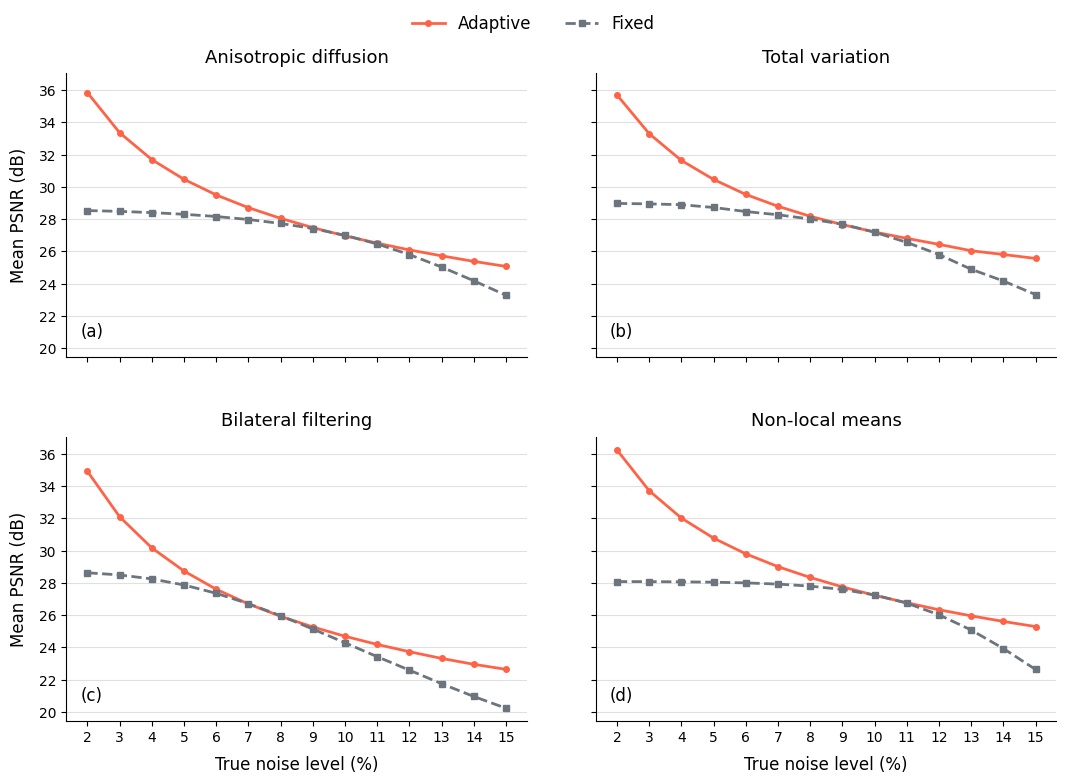

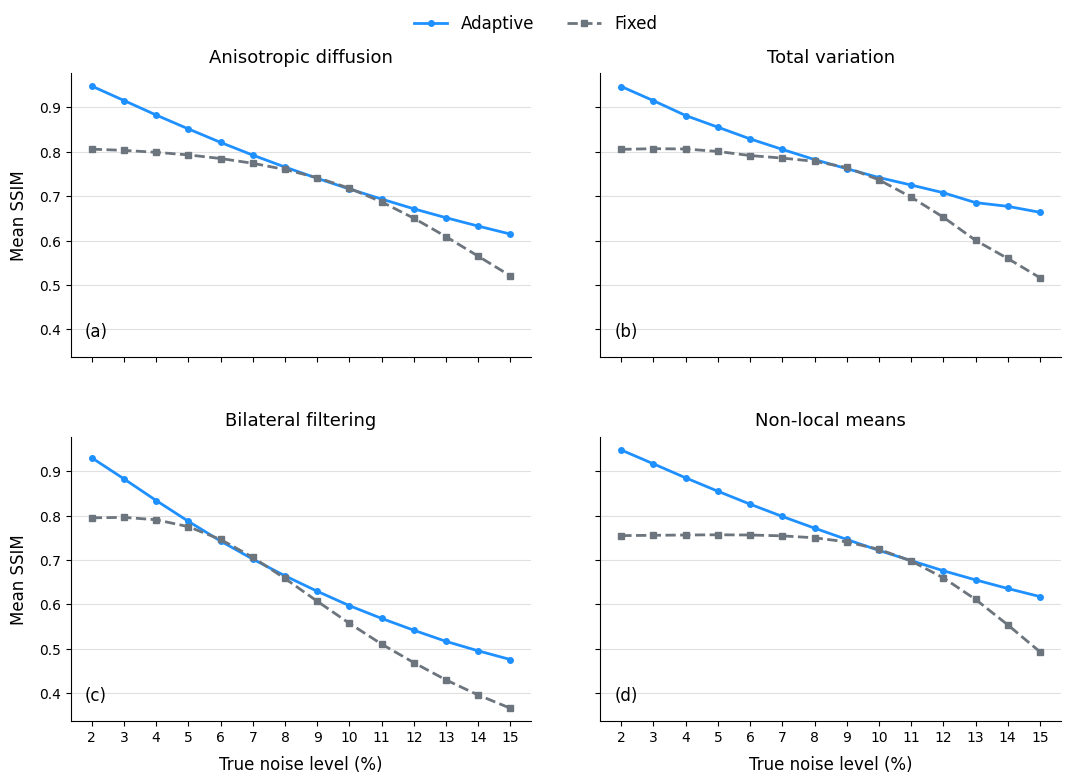

In [11]:
# Adaptive vs Fixed PSNR
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
styles = {
    "Adaptive": {"color": "#FF6347", "linestyle": "-", "marker": "o"},
    "Fixed": {"color": "#6c757d", "linestyle": "--", "marker": "s"}
}

for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
    current = psnr_summary[psnr_summary["method"] == method]
    for strategy in ["Adaptive", "Fixed"]:
        values = current[current["strategy"] == strategy]
        ax.plot(values["true_noise_percent"], values["psnr"], linewidth=2, markersize=4,
                label=strategy, **styles[strategy])

    ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
    ax.set_xticks(noise_levels)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.03, 0.06, f"({chr(97 + panel)})", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12)

for ax in axes[:, 0]:
    ax.set_ylabel("Mean PSNR (dB)", fontsize=12, labelpad=8)
for ax in axes[1]:
    ax.set_xlabel("True noise level (%)", fontsize=12, labelpad=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, top=0.91, bottom=0.10, wspace=0.15, hspace=0.28)
fig.savefig(result_dir / "adaptive_vs_fixed_psnr.png", dpi=300, bbox_inches="tight")
plt.show()


# Adaptive vs Fixed SSIM
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
styles = {
    "Adaptive": {"color": "#1E90FF", "linestyle": "-", "marker": "o"},
    "Fixed": {"color": "#6c757d", "linestyle": "--", "marker": "s"}
}

for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
    current = ssim_summary[ssim_summary["method"] == method]
    for strategy in ["Adaptive", "Fixed"]:
        values = current[current["strategy"] == strategy]
        ax.plot(values["true_noise_percent"], values["ssim"], linewidth=2, markersize=4,
                label=strategy, **styles[strategy])

    ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
    ax.set_xticks(noise_levels)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.03, 0.06, f"({chr(97 + panel)})", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12)

for ax in axes[:, 0]:
    ax.set_ylabel("Mean SSIM", fontsize=12, labelpad=8)
for ax in axes[1]:
    ax.set_xlabel("True noise level (%)", fontsize=12, labelpad=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, top=0.91, bottom=0.10, wspace=0.15, hspace=0.28)
fig.savefig(result_dir / "adaptive_vs_fixed_ssim.png", dpi=300, bbox_inches="tight")
plt.show()

## 5.2.2 Adaptive vs Known-noise

Both strategies use the same mappings. Adaptive uses the estimated noise level. Known-noise uses the true level.

In [12]:
def evaluate_known_noise_case(image_index, image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_percent / 100, seed=make_case_seed(image_index, noise_percent)
    ).astype(np.float32)

    rows = []
    for method in METHOD_ORDER:
        denoised_image = denoise_mapped(noisy_image, method, noise_percent)

        if denoised_image.shape != clean_image.shape:
            raise ValueError(f"{method} returned an unexpected shape")
        if not np.isfinite(denoised_image).all():
            raise ValueError(f"{method} returned a non-finite value")

        rows.append({
            "image": image_name, "image_index": image_index,
            "true_noise_percent": noise_percent, "method": method, "strategy": "Known-noise",
            "psnr": peak_signal_noise_ratio(clean_image, denoised_image, data_range=1.0),
            "ssim": structural_similarity(clean_image, denoised_image, data_range=1.0)
        })

    return rows


known_outputs = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_known_noise_case)(image_index, image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_index, (image_name, clean_image) in enumerate(test_images)
)

known_noise_results = pd.DataFrame([row for case_rows in known_outputs for row in case_rows])
result_columns = ["image", "image_index", "true_noise_percent", "method", "strategy", "psnr", "ssim"]

adaptive_results = test_results.loc[test_results["strategy"] == "Adaptive", result_columns].copy()
adaptive_known_results = pd.concat(
    [adaptive_results, known_noise_results[result_columns]], ignore_index=True
)
adaptive_known_results = adaptive_known_results.sort_values(
    ["method", "strategy", "true_noise_percent", "image_index"]
).reset_index(drop=True)

expected_rows = num_test_images * len(noise_levels) * len(METHOD_ORDER) * 2
if len(adaptive_known_results) != expected_rows:
    raise RuntimeError(f"Expected {expected_rows} rows, but obtained {len(adaptive_known_results)}")

print("Completed Known-noise cases:", len(known_outputs))
print("Combined metric records:", len(adaptive_known_results))
display(adaptive_known_results.head())

[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    8.0s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   27.4s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   53.4s
[Parallel(n_jobs=16)]: Done 418 tasks      | elapsed:  1.4min
[Parallel(n_jobs=16)]: Done 616 tasks      | elapsed:  1.9min
[Parallel(n_jobs=16)]: Done 850 tasks      | elapsed:  2.5min
[Parallel(n_jobs=16)]: Done 1120 tasks      | elapsed:  3.4min


Completed Known-noise cases: 1400
Combined metric records: 11200


[Parallel(n_jobs=16)]: Done 1400 out of 1400 | elapsed:  4.2min finished


,image,image_index,true_noise_percent,method,strategy,psnr,ssim
0,001,0,2,AD,Adaptive,32.579760,0.927210
1,002,1,2,AD,Adaptive,37.291542,0.955519
2,003,2,2,AD,Adaptive,37.171387,0.945708
3,004,3,2,AD,Adaptive,37.324663,0.957255
4,005,4,2,AD,Adaptive,35.361967,0.960693


### Performance gap

The gap is Known-noise minus Adaptive.

In [13]:
group_columns = ["method", "strategy", "true_noise_percent"]

known_level_summary = adaptive_known_results.groupby(group_columns, as_index=False).agg(
    psnr=("psnr", "mean"), ssim=("ssim", "mean")
)
known_psnr_summary = known_level_summary[group_columns + ["psnr"]]
known_ssim_summary = known_level_summary[group_columns + ["ssim"]]

known_psnr_wide = known_psnr_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="psnr"
).reset_index()
known_ssim_wide = known_ssim_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="ssim"
).reset_index()

known_comparison = known_psnr_wide.merge(
    known_ssim_wide, on=["method", "true_noise_percent"], suffixes=("_psnr", "_ssim")
)
known_comparison["psnr_gap"] = known_comparison["Known-noise_psnr"] - known_comparison["Adaptive_psnr"]
known_comparison["ssim_gap"] = known_comparison["Known-noise_ssim"] - known_comparison["Adaptive_ssim"]

known_method_summary = (
    known_comparison.groupby("method", as_index=False)
    .agg(
        adaptive_mean_psnr=("Adaptive_psnr", "mean"),
        known_mean_psnr=("Known-noise_psnr", "mean"),
        mean_psnr_gap=("psnr_gap", "mean"),
        largest_psnr_gap=("psnr_gap", "max"),
        adaptive_mean_ssim=("Adaptive_ssim", "mean"),
        known_mean_ssim=("Known-noise_ssim", "mean"),
        mean_ssim_gap=("ssim_gap", "mean"),
        largest_ssim_gap=("ssim_gap", "max")
    )
    .set_index("method").loc[METHOD_ORDER].reset_index()
)

known_method_summary["Method"] = known_method_summary["method"].map(METHOD_LABELS)

psnr_gap_table = known_method_summary[[
    "Method", "adaptive_mean_psnr", "known_mean_psnr", "mean_psnr_gap", "largest_psnr_gap"
]].rename(columns={
    "adaptive_mean_psnr": "Adaptive PSNR (dB)",
    "known_mean_psnr": "Known-noise PSNR (dB)",
    "mean_psnr_gap": "Mean gap (dB)",
    "largest_psnr_gap": "Largest gap (dB)"
})

ssim_gap_table = known_method_summary[[
    "Method", "adaptive_mean_ssim", "known_mean_ssim", "mean_ssim_gap", "largest_ssim_gap"
]].rename(columns={
    "adaptive_mean_ssim": "Adaptive SSIM",
    "known_mean_ssim": "Known-noise SSIM",
    "mean_ssim_gap": "Mean gap",
    "largest_ssim_gap": "Largest gap"
})

display(psnr_gap_table.round({
    "Adaptive PSNR (dB)": 3, "Known-noise PSNR (dB)": 3,
    "Mean gap (dB)": 4, "Largest gap (dB)": 4
}))
display(ssim_gap_table.round({
    "Adaptive SSIM": 4, "Known-noise SSIM": 4, "Mean gap": 5, "Largest gap": 5
}))

,Method,Adaptive PSNR (dB),Known-noise PSNR (dB),Mean gap (dB),Largest gap (dB)
0,Anisotropic diffusion,28.626,28.704,0.0781,0.3146
1,Total variation,28.790,28.882,0.0923,0.3933
2,Bilateral filtering,26.634,26.687,0.0537,0.1703
3,Non-local means,28.915,28.984,0.0692,0.2553


,Method,Adaptive SSIM,Known-noise SSIM,Mean gap,Largest gap
0,Anisotropic diffusion,0.7640,0.7667,0.00266,0.00498
1,Total variation,0.7841,0.7868,0.00269,0.00588
2,Bilateral filtering,0.6690,0.6702,0.00120,0.00187
3,Non-local means,0.7678,0.7721,0.00433,0.00809


### Adaptive and Known-noise curves

The figures compare both strategies on the same PSNR and SSIM scales.

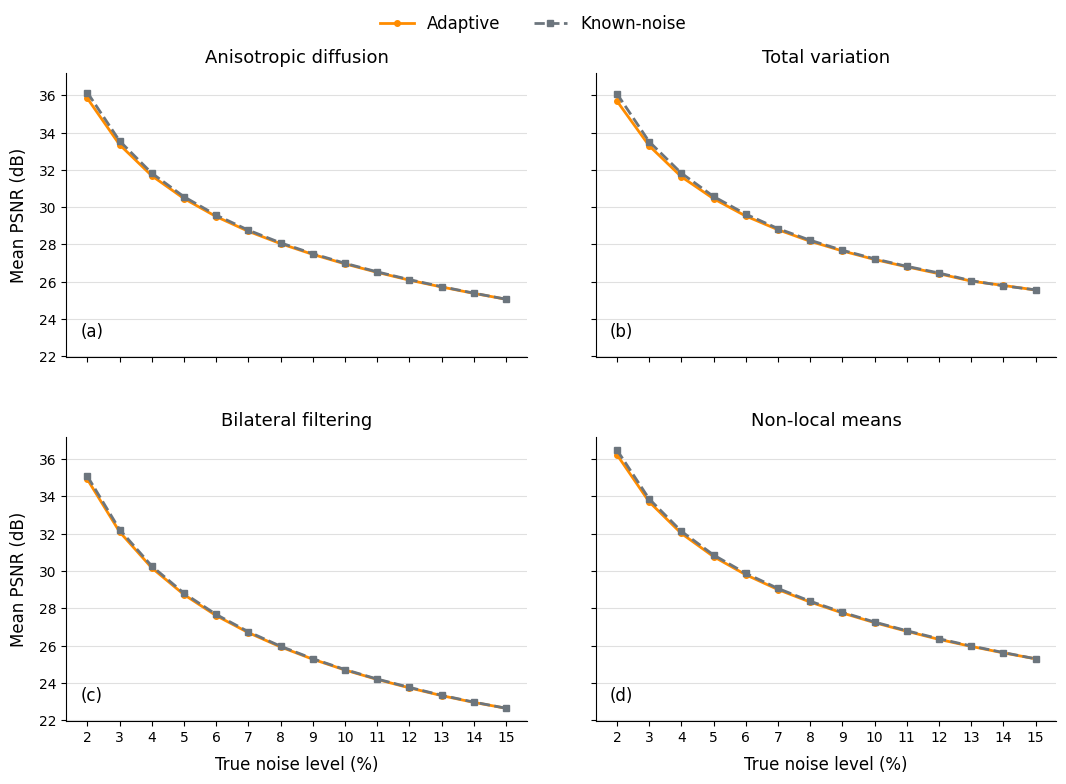

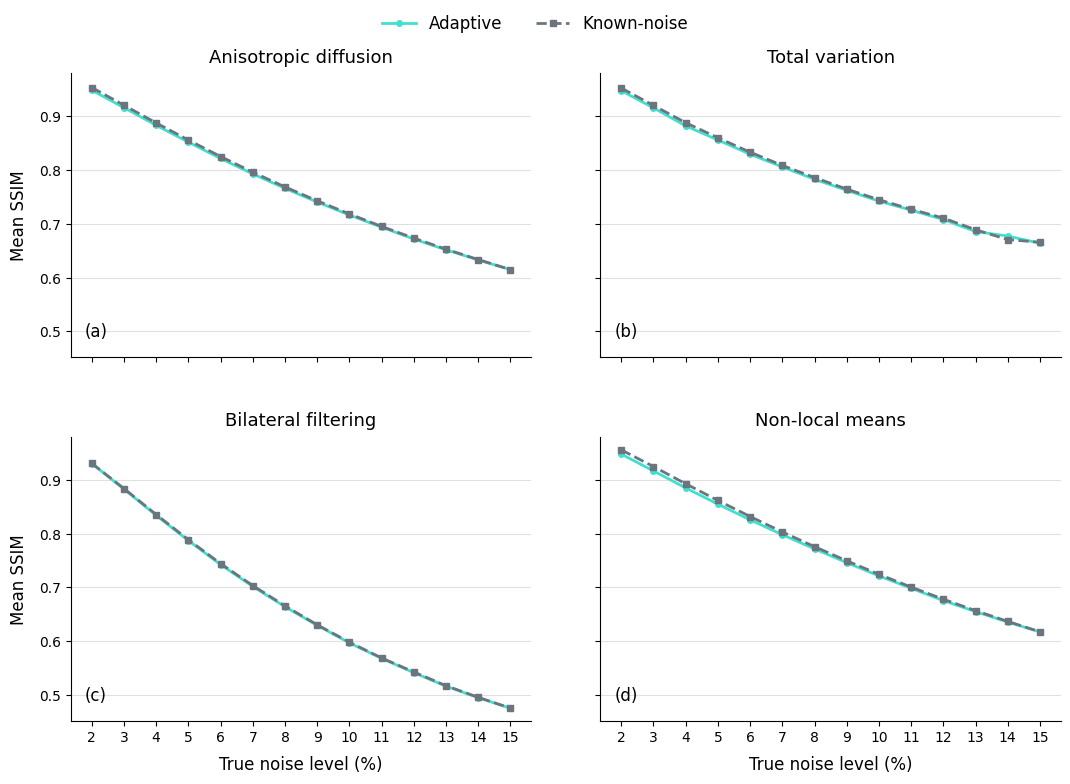

In [14]:
# Adaptive vs Known-noise PSNR
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
styles = {
    "Adaptive": {"color": "#FF8C00", "linestyle": "-", "marker": "o"},
    "Known-noise": {"color": "#6c757d", "linestyle": "--", "marker": "s"}
}

for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
    current = known_psnr_summary[known_psnr_summary["method"] == method]
    for strategy in ["Adaptive", "Known-noise"]:
        values = current[current["strategy"] == strategy]
        ax.plot(values["true_noise_percent"], values["psnr"], linewidth=2, markersize=4,
                label=strategy, **styles[strategy])

    ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
    ax.set_xticks(noise_levels)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.03, 0.06, f"({chr(97 + panel)})", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12)

for ax in axes[:, 0]:
    ax.set_ylabel("Mean PSNR (dB)", fontsize=12, labelpad=8)
for ax in axes[1]:
    ax.set_xlabel("True noise level (%)", fontsize=12, labelpad=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, top=0.91, bottom=0.10, wspace=0.15, hspace=0.28)
fig.savefig(result_dir / "adaptive_vs_known_noise_psnr.png", dpi=300, bbox_inches="tight")
plt.show()


# Adaptive vs Known-noise SSIM
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
styles = {
    "Adaptive": {"color": "#40E0D0", "linestyle": "-", "marker": "o"},
    "Known-noise": {"color": "#6c757d", "linestyle": "--", "marker": "s"}
}

for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
    current = known_ssim_summary[known_ssim_summary["method"] == method]
    for strategy in ["Adaptive", "Known-noise"]:
        values = current[current["strategy"] == strategy]
        ax.plot(values["true_noise_percent"], values["ssim"], linewidth=2, markersize=4,
                label=strategy, **styles[strategy])

    ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
    ax.set_xticks(noise_levels)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.03, 0.06, f"({chr(97 + panel)})", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12)

for ax in axes[:, 0]:
    ax.set_ylabel("Mean SSIM", fontsize=12, labelpad=8)
for ax in axes[1]:
    ax.set_xlabel("True noise level (%)", fontsize=12, labelpad=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.subplots_adjust(left=0.08, right=0.98, top=0.91, bottom=0.10, wspace=0.15, hspace=0.28)
fig.savefig(result_dir / "adaptive_vs_known_noise_ssim.png", dpi=300, bbox_inches="tight")
plt.show()

## 5.2.3 Adaptive vs Oracle

Oracle selects the highest-PSNR primary parameter for each test case within the calibrated search range. Other settings remain fixed.

In [15]:
oracle_dir = project_dir / "results" / "Chapter5_SearchOracleParameter"
oracle_path = oracle_dir / "oracle_results.csv"

if not oracle_path.exists():
    raise FileNotFoundError("Run Chapter5_SearchOracleParameter first")

oracle_results = pd.read_csv(oracle_path)
oracle_results["strategy"] = "Oracle"

expected_oracle_rows = num_test_images * len(noise_levels) * len(METHOD_ORDER)
if len(oracle_results) != expected_oracle_rows:
    raise RuntimeError(f"Expected {expected_oracle_rows} Oracle rows, but obtained {len(oracle_results)}")

result_columns = ["image", "image_index", "true_noise_percent", "method", "strategy", "psnr", "ssim"]
adaptive_results = test_results.loc[test_results["strategy"] == "Adaptive", result_columns].copy()

adaptive_oracle_results = pd.concat(
    [adaptive_results, oracle_results[result_columns]], ignore_index=True
)
adaptive_oracle_results = adaptive_oracle_results.sort_values(
    ["method", "strategy", "true_noise_percent", "image_index"]
).reset_index(drop=True)

print("Oracle records:", len(oracle_results))
print("Combined metric records:", len(adaptive_oracle_results))
display(adaptive_oracle_results.head())

Oracle records: 5600
Combined metric records: 11200


,image,image_index,true_noise_percent,method,strategy,psnr,ssim
0,001,0,2,AD,Adaptive,32.579760,0.927210
1,002,1,2,AD,Adaptive,37.291542,0.955519
2,003,2,2,AD,Adaptive,37.171387,0.945708
3,004,3,2,AD,Adaptive,37.324663,0.957255
4,005,4,2,AD,Adaptive,35.361967,0.960693


### Performance gap

The gap is Oracle minus Adaptive.

In [16]:
group_columns = ["method", "strategy", "true_noise_percent"]

oracle_level_summary = adaptive_oracle_results.groupby(group_columns, as_index=False).agg(
    psnr=("psnr", "mean"), ssim=("ssim", "mean")
)
oracle_psnr_summary = oracle_level_summary[group_columns + ["psnr"]]
oracle_ssim_summary = oracle_level_summary[group_columns + ["ssim"]]

oracle_psnr_wide = oracle_psnr_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="psnr"
).reset_index()
oracle_ssim_wide = oracle_ssim_summary.pivot(
    index=["method", "true_noise_percent"], columns="strategy", values="ssim"
).reset_index()

oracle_comparison = oracle_psnr_wide.merge(
    oracle_ssim_wide, on=["method", "true_noise_percent"], suffixes=("_psnr", "_ssim")
)
oracle_comparison["psnr_gap"] = oracle_comparison["Oracle_psnr"] - oracle_comparison["Adaptive_psnr"]
oracle_comparison["ssim_gap"] = oracle_comparison["Oracle_ssim"] - oracle_comparison["Adaptive_ssim"]

adaptive_oracle_method_summary = (
    oracle_comparison.groupby("method", as_index=False)
    .agg(
        adaptive_mean_psnr=("Adaptive_psnr", "mean"),
        oracle_mean_psnr=("Oracle_psnr", "mean"),
        mean_psnr_gap=("psnr_gap", "mean"),
        largest_psnr_gap=("psnr_gap", "max"),
        adaptive_mean_ssim=("Adaptive_ssim", "mean"),
        oracle_mean_ssim=("Oracle_ssim", "mean"),
        mean_ssim_gap=("ssim_gap", "mean"),
        largest_ssim_gap=("ssim_gap", "max")
    )
    .set_index("method").loc[METHOD_ORDER].reset_index()
)

adaptive_oracle_method_summary["Method"] = adaptive_oracle_method_summary["method"].map(METHOD_LABELS)

psnr_oracle_table = adaptive_oracle_method_summary[[
    "Method", "adaptive_mean_psnr", "oracle_mean_psnr", "mean_psnr_gap", "largest_psnr_gap"
]].rename(columns={
    "adaptive_mean_psnr": "Adaptive PSNR (dB)",
    "oracle_mean_psnr": "Oracle PSNR (dB)",
    "mean_psnr_gap": "Mean gap (dB)",
    "largest_psnr_gap": "Largest gap (dB)"
})

ssim_oracle_table = adaptive_oracle_method_summary[[
    "Method", "adaptive_mean_ssim", "oracle_mean_ssim", "mean_ssim_gap", "largest_ssim_gap"
]].rename(columns={
    "adaptive_mean_ssim": "Adaptive SSIM",
    "oracle_mean_ssim": "Oracle SSIM",
    "mean_ssim_gap": "Mean gap",
    "largest_ssim_gap": "Largest gap"
})

display(psnr_oracle_table.round({
    "Adaptive PSNR (dB)": 3, "Oracle PSNR (dB)": 3,
    "Mean gap (dB)": 4, "Largest gap (dB)": 4
}))
display(ssim_oracle_table.round({
    "Adaptive SSIM": 4, "Oracle SSIM": 4, "Mean gap": 5, "Largest gap": 5
}))

,Method,Adaptive PSNR (dB),Oracle PSNR (dB),Mean gap (dB),Largest gap (dB)
0,Anisotropic diffusion,28.626,28.803,0.1770,0.3264
1,Total variation,28.790,29.056,0.2665,0.4391
2,Bilateral filtering,26.634,26.809,0.1751,0.2278
3,Non-local means,28.915,29.042,0.1276,0.2621


,Method,Adaptive SSIM,Oracle SSIM,Mean gap,Largest gap
0,Anisotropic diffusion,0.7640,0.7729,0.00884,0.01125
1,Total variation,0.7841,0.7959,0.01176,0.02085
2,Bilateral filtering,0.6690,0.6784,0.00931,0.01315
3,Non-local means,0.7678,0.7782,0.01046,0.01257


### Adaptive and Oracle curves

The figures show the remaining gap across the test noise levels.

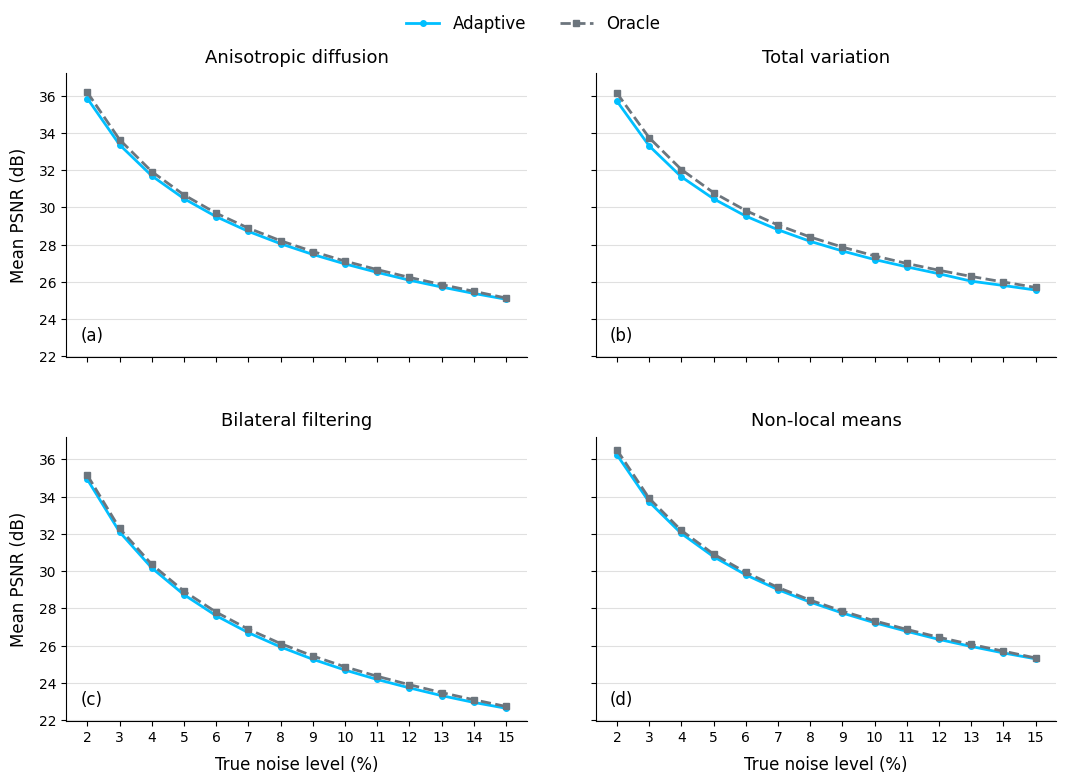

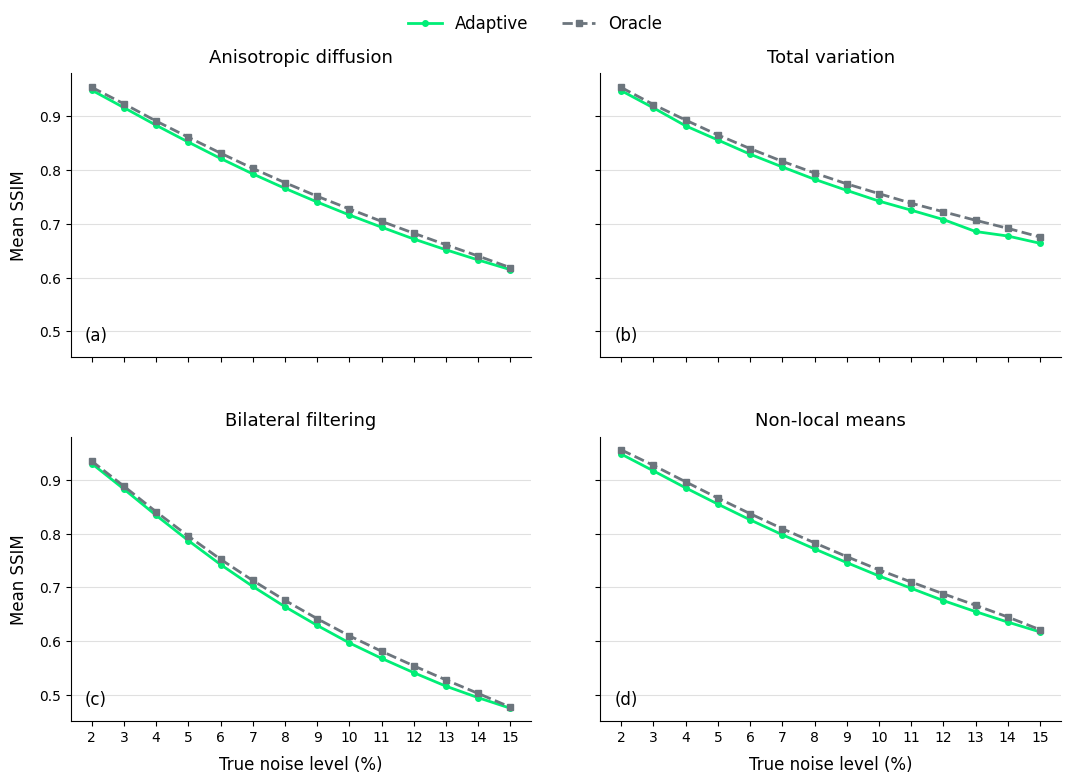

In [27]:
def plot_adaptive_oracle(summary, metric, ylabel, output_name, adaptive_color):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
    styles = {
        "Adaptive": {"color": adaptive_color, "linestyle": "-", "marker": "o"},
        "Oracle": {"color": "#6c757d", "linestyle": "--", "marker": "s"}
    }

    for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
        current = summary[summary["method"] == method]
        for strategy in ["Adaptive", "Oracle"]:
            values = current[current["strategy"] == strategy]
            ax.plot(values["true_noise_percent"], values[metric], linewidth=2, markersize=4,
                    label=strategy, **styles[strategy])

        ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
        ax.set_xticks(noise_levels)
        ax.tick_params(axis="both", labelsize=10)
        ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.text(0.03, 0.06, f"({chr(97 + panel)})", transform=ax.transAxes, fontsize=12)

    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel, fontsize=12, labelpad=8)
    for ax in axes[1]:
        ax.set_xlabel("True noise level (%)", fontsize=12, labelpad=8)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=12)
    fig.subplots_adjust(left=0.08, right=0.98, top=0.91, bottom=0.10, wspace=0.15, hspace=0.28)
    fig.savefig(result_dir / output_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_adaptive_oracle(oracle_psnr_summary, "psnr", "Mean PSNR (dB)",
                     "adaptive_vs_oracle_psnr.png", "#00BFFF")
plot_adaptive_oracle(oracle_ssim_summary, "ssim", "Mean SSIM",
                     "adaptive_vs_oracle_ssim.png", "#00EE76")